# Validation méthode estimation par historique

Vérifier le fonctionnement de Agent.estimate_from_history() et Estimator.estimate_from_history() sur les données réelles de Toulouse (OpenData 2020), ainsi que le marquage des valeurs estimées (is_estimate).

Pour un timestamp t dont la valeur réelle est connue, on demande à l'agent d'estimer la valeur à t en n'utilisant que son historique antérieur à t (garanti par _get_valid_values(before=t)). On compare ensuite estimation et valeur réelle.

In [1]:
# Uncomment if dependencies are not installed
# %pip install -r requirements.txt

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt

from hybridiot import MeteoDataset, Agent, Estimator

In [3]:
# Chargement du dataset
ds = MeteoDataset.from_csv('../data/toulouse_meteo_2020(35.000).csv')
print(ds.describe())

  Sampling frequency detected: 15 min
MeteoDataset 'toulouse_meteo_2020(35.000)'
  Source      : ../data/toulouse_meteo_2020(35.000).csv
  Sensors     : 6 stations
  Data types  : ['temperature', 'humidite', 'pression', 'pluie', 'pluie_intensite_max']
  Tensor      : (5, 35136, 6)  (n_types × n_timesteps × n_sensors)
  Timesteps   : 35136 (every 15 min)
  Time range  : 2020-01-01 00:00:00+00:00 -> 2020-12-31 23:45:00+00:00
  NaN rate    : 1.87%


In [4]:
# Création d'un agent température et chargement de son historique

agent = Agent(id='Toulouse Basso Cambo', position=(43.57, 1.39, 157.20), data_type='temperature')
agent.load_from_dataset(ds)

print(f'Dataset local : {len(agent.dataset)} valeurs')
print(f'Premier timestamp : {agent.dataset[0][0]}')
print(f'Dernier timestamp : {agent.dataset[-1][0]}')
print(f'Valeurs estimées  : {len(agent.estimated_timestamps)} (attendu : 0, données initiales non marquées)')

Dataset local : 35136 valeurs
Premier timestamp : 2020-01-01 00:00:00+00:00
Dernier timestamp : 2020-12-31 23:45:00+00:00
Valeurs estimées  : 0 (attendu : 0, données initiales non marquées)


## 1. Cas nominal: une estimation ponctuelle

On choisit un timestamp dans la seconde moitié du dataset (assez d'historique), on estime, et on compare à la valeur réelle.

In [5]:
# Timestamp cible: aux 3/4 du dataset
idx_target = (len(agent.dataset) * 3) // 4
ts_target, real_value = agent.dataset[idx_target]

estimate = agent.estimate_from_history(ts_target)

print(f'Timestamp cible : {ts_target}')
print(f'Valeur réelle   : {real_value:.2f}')
print(f'Valeur estimée  : {estimate:.2f}')
print(f'Erreur absolue  : {abs(estimate - real_value):.2f}')

Timestamp cible : 2020-10-01 12:00:00+00:00
Valeur réelle   : 17.60
Valeur estimée  : 17.70
Erreur absolue  : 0.10


## 2. Évaluation systématique: MAE sur N timestamps

On répète l'estimation sur N timestamps répartis dans la seconde moitié du dataset, et on calcule l'erreur absolue moyenne (MAE).
Baseline de comparaison: la persistance (E_t = valeur précédente), c'est-à-dire ce que ferait l'agent sans aucune correction (w_t = 0). La méthode par historique doit faire au moins aussi bien.

In [6]:
N = 200
half = len(agent.dataset) // 2
step = (len(agent.dataset) - half) // N
indices = range(half, len(agent.dataset), step)

errors_method, errors_persistence = [], []
results = []  # (ts, real, estimate) pour le plot
skipped = 0

for idx in indices:
    ts, real = agent.dataset[idx]
    if real is None or (isinstance(real, float) and np.isnan(real)):
        skipped += 1
        continue

    est = agent.estimate_from_history(ts)
    if est is None:
        skipped += 1
        continue

    # baseline persistance: dernière valeur valide avant ts
    valid_before = agent._get_valid_values(before=ts)
    persistence = valid_before[-1]

    errors_method.append(abs(est - real))
    errors_persistence.append(abs(persistence - real))
    results.append((ts, real, est))

mae_method = np.mean(errors_method)
mae_persistence = np.mean(errors_persistence)

print(f'Estimations évaluées : {len(errors_method)} (ignorées : {skipped})')
print(f'MAE méthode historique : {mae_method:.3f}')
print(f'MAE persistance        : {mae_persistence:.3f}')
print(f'Amélioration           : {(1 - mae_method/mae_persistence)*100:+.1f}%')

Estimations évaluées : 196 (ignorées : 6)
MAE méthode historique : 0.172
MAE persistance        : 0.223
Amélioration           : +22.9%


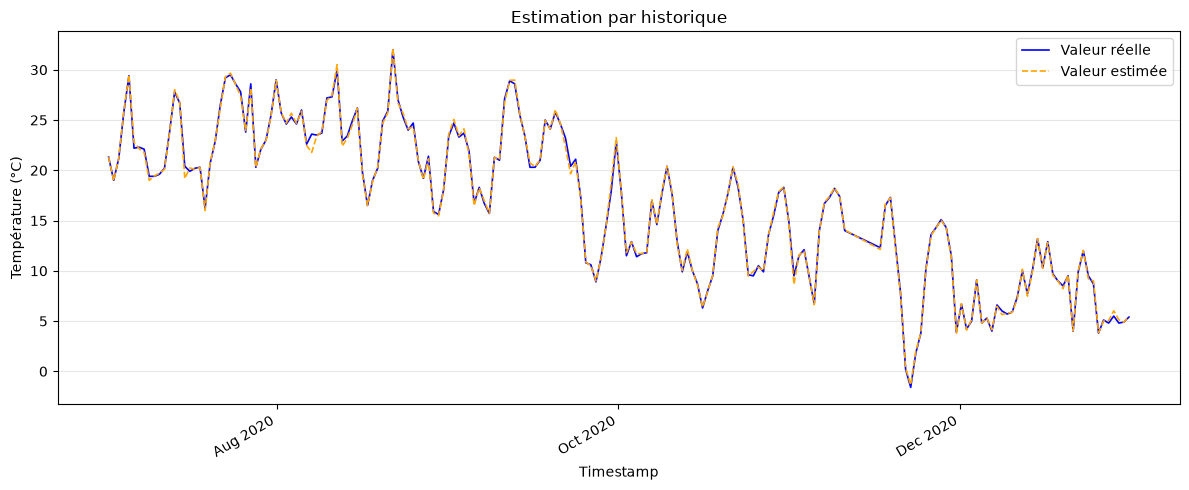

In [7]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(1, 1, figsize=(12, 5))

plot_ts, plot_real, plot_est = zip(*results)

axes.plot(plot_ts, plot_real, label='Valeur réelle', color='blue', linewidth=1.2)
axes.plot(plot_ts, plot_est, label='Valeur estimée', color='orange', linewidth=1.2, linestyle='--')
axes.set_title(f'Estimation par historique')
axes.set_xlabel('Timestamp')
axes.set_ylabel('Température (°C)')
axes.legend()
axes.grid(axis='y', alpha=0.3)
axes.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(axes.xaxis.get_majorticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

## 3. Marquage des valeurs estimées: flag is_estimated
On vérifie:
- les valeurs perçues ne sont pas marquées 
- les valeurs estimées sont marquées

In [8]:
# Agent de test avec un petit historique perçu
agent_flag = Agent(id='flag_station', data_type='temperature', position=(0, 0, 0))
t0 = datetime(2020, 7, 1, 12, 0)
for i in range(20):
    agent_flag.add_value(value=20.0 + 0.1*i, timestamp=t0 + timedelta(minutes=15*i))

print('Valeurs dans le dataset :', len(agent_flag.dataset))
print('Valeurs marquées estimées :', len(agent_flag.estimated_timestamps))

# Workflow complet: estimation puis ajout marqué
ts_missing = t0 + timedelta(minutes=15*20)
est = agent_flag.estimate_from_history(ts_missing)
print(f'\nValeur estimée à {ts_missing} : {est:.2f}')

# ajouter l'estimation au dataset
agent_flag.add_value(value=est, timestamp=ts_missing, is_estimate=True)

print('is_estimated(ts_missing) :', agent_flag.is_estimated(ts_missing))
print('is_estimated(t0)         :', agent_flag.is_estimated(t0))
print('\nLe marquage des valeurs estimées fonctionne correctement.')

Valeurs dans le dataset : 20
Valeurs marquées estimées : 0

Valeur estimée à 2020-07-01 17:00:00 : 21.90
is_estimated(ts_missing) : True
is_estimated(t0)         : False

Le marquage des valeurs estimées fonctionne correctement.


## 4. Cas limites

In [9]:
# Cas 1: agent sans aucune donnée
agent_empty = Agent(id='empty_station', data_type='temperature', position=(0, 0, 0))
result = agent_empty.estimate_from_history(datetime(2020, 7, 1, 12, 0))
print('Agent vide :', result)

# Cas 2: agent avec 15 valeurs (< 16 requises, si WINDOWS_SIZE = 16)
agent_short = Agent(id='short_station', data_type='temperature', position=(0, 0, 0))
t0 = datetime(2020, 7, 1, 12, 0)
for i in range(15):
    agent_short.add_value(value=20.0 + 0.1*i, timestamp=t0 + timedelta(minutes=15*i))
result = agent_short.estimate_from_history(t0 + timedelta(minutes=15*15))
print('15 valeurs (< 16) :', result)

# Cas 3: agent avec exactement 16 valeurs → estimation possible
agent_short.add_value(value=21.5, timestamp=t0 + timedelta(minutes=15*15))
result = agent_short.estimate_from_history(t0 + timedelta(minutes=15*16))
print('16 valeurs (= min) :', f'{result:.2f}')

# Cas 4: timestamp au tout début de l'historique de l'agent réel
ts_debut = agent.dataset[5][0]
result = agent.estimate_from_history(ts_debut)
print('Début d\'historique :', result)

print('\nTous les cas limites retournent None sans exception.')

Agent vide : None
15 valeurs (< 16) : None
16 valeurs (= min) : 21.60
Début d'historique : None

Tous les cas limites retournent None sans exception.
